# Parte 1 – El modelo BG/NBD: verosimilitud y simulación

**Autor:** Herman Andrés Echeverría Rojas · Grupo 1

**Declaración de uso de IA:** se utilizó Claude (Anthropic) como herramienta de apoyo para comprender lo que pedía cada inciso del enunciado y como asistencia al escribir y depurar el código. El análisis, la verificación de resultados y su interpretación fueron revisados por el autor.

**Referencias principales**

- Fader, P. S., Hardie, B. G. S. y Lee, K. L. (2005). "Counting Your Customers" the Easy Way: An Alternative to the Pareto/NBD Model. *Marketing Science*, 24(2), 275–284.
- Fader, P. S., Hardie, B. G. S. y Lee, K. L. (2005). *Implementing the BG/NBD Model for Customer Base Analysis in Excel*. http://brucehardie.com/notes/004/

Este notebook contiene la derivación de la verosimilitud (1.1 y 1.2), la verificación del código de `src/bgnbd.py` y el estudio de simulación de recuperación de parámetros (1.3). El ajuste a CDNOW y su interpretación están en `02_ajuste_cdnow.ipynb`.

In [1]:
import sys, json, warnings
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datos import cargar_cdnow, resumen_clientes
from bgnbd import loglik_bgnbd, ajustar_bgnbd, PARAMS_ARTICULO, NOMBRES

trans = cargar_cdnow("../data/CDNOW_sample.txt")
res = resumen_clientes(trans, "1997-09-30", "1998-06-30")
x, tx, T = res["x"].values, res["tx"].values, res["T"].values
params = json.load(open("../resultados/params_cdnow.json"))
print(f"{len(res)} clientes; parámetros cargados de params_cdnow.json: {params}")

2357 clientes; parámetros cargados de params_cdnow.json: {'r': 0.243, 'alpha': 4.414, 'a': 0.793, 'b': 2.426}


## 1.1 Verosimilitud de un cliente

**Supuestos del BG/NBD** (Fader, Hardie y Lee, 2005, §3):

1. Mientras está vivo, el cliente compra según un proceso de Poisson con tasa $\lambda$; las esperas entre compras son exponenciales: $f(t_j \mid t_{j-1};\lambda) = \lambda e^{-\lambda (t_j - t_{j-1})}$.
2. $\lambda \sim \text{Gamma}(r, \alpha)$ entre clientes, con densidad $f(\lambda) = \dfrac{\alpha^r \lambda^{r-1} e^{-\alpha\lambda}}{\Gamma(r)}$ ($\alpha$ es una **tasa**).
3. Justo después de cada compra **repetida**, el cliente muere con probabilidad $p$.
4. $p \sim \text{Beta}(a, b)$ entre clientes, con densidad $f(p) = \dfrac{p^{a-1}(1-p)^{b-1}}{B(a,b)}$.
5. $\lambda$ y $p$ son independientes.

El tiempo se mide desde la primera compra del cliente ($t = 0$), así que solo se modelan las compras repetidas. Supongamos que el cliente hizo $x$ compras repetidas en $t_1 < t_2 < \dots < t_x$, todas dentro de $(0, T]$. Hay exactamente **dos historias** que producen esa observación:

**(a) Sigue vivo en $T$.** La primera compra en $t_1$ aporta $\lambda e^{-\lambda t_1}$. Cada compra siguiente exige haber sobrevivido a la anterior: $(1-p)\,\lambda e^{-\lambda(t_j - t_{j-1})}$. Después de la $x$-ésima compra también sobrevivió $(1-p)$ y no compró nada en $(t_x, T]$, lo que tiene probabilidad $e^{-\lambda(T - t_x)}$. Al multiplicar, los exponentes se suman de forma telescópica:

$$(1-p)^x\,\lambda^x\,e^{-\lambda T}.$$

**(b) Murió justo después de la compra en $t_x$.** Sobrevivió a las primeras $x-1$ compras, $(1-p)^{x-1}$, y murió en la $x$-ésima con probabilidad $p$. Después de morir ya no puede comprar, así que no hay factor de supervivencia en $(t_x, T]$:

$$p\,(1-p)^{x-1}\,\lambda^x\,e^{-\lambda t_x}.$$

Esta historia solo existe si $x > 0$: en el BG/NBD **no se puede morir antes de una compra repetida**. Por eso aparece $\delta_{x>0}$. Sumando las dos historias (son excluyentes):

$$L(\lambda, p \mid x, t_x, T) = (1-p)^x \lambda^x e^{-\lambda T} + \delta_{x>0}\; p(1-p)^{x-1} \lambda^x e^{-\lambda t_x}. \qquad (1)$$

Dos observaciones importantes:

- Los tiempos intermedios $t_1, \dots, t_{x-1}$ desaparecieron. La verosimilitud depende solo de **$(x, t_x, T)$**: frecuencia, recencia y antigüedad son estadísticos suficientes.
- Si $x = 0$, $L = e^{-\lambda T}$: la probabilidad de no comprar en $(0, T]$ estando vivo. **Este término no contiene a $p$**, así que los clientes sin compras repetidas no aportan información sobre la muerte. Esto vuelve a aparecer en 1.3.

## 1.2 Verosimilitud de un cliente elegido al azar

No observamos $\lambda$ ni $p$, así que los integramos contra sus distribuciones. Por independencia (supuesto 5), cada término de (1) se separa en una integral en $\lambda$ y otra en $p$:

$$L(r,\alpha,a,b \mid x, t_x, T) = \int_0^1\!\!\int_0^\infty L(\lambda, p \mid x, t_x, T)\, f(\lambda \mid r, \alpha)\, f(p \mid a, b)\; d\lambda\, dp.$$

**Integral en $\lambda$ (mezcla gamma–Poisson).** Para $s \in \{T, t_x\}$:

$$\int_0^\infty \lambda^x e^{-\lambda s}\, \frac{\alpha^r \lambda^{r-1} e^{-\alpha\lambda}}{\Gamma(r)}\, d\lambda
= \frac{\alpha^r}{\Gamma(r)} \int_0^\infty \lambda^{r+x-1} e^{-(\alpha + s)\lambda}\, d\lambda
= \frac{\Gamma(r+x)\,\alpha^r}{\Gamma(r)\,(\alpha+s)^{r+x}}.$$

El integrando es el núcleo de una $\text{Gamma}(r+x,\ \alpha+s)$, cuya constante de normalización es $\Gamma(r+x)/(\alpha+s)^{r+x}$. Es el mismo cálculo que da la binomial negativa en los GLM.

**Integrales en $p$ (definición de la función beta).** Con $B(u, v) = \int_0^1 p^{u-1}(1-p)^{v-1}dp$:

$$\int_0^1 (1-p)^x\, \frac{p^{a-1}(1-p)^{b-1}}{B(a,b)}\, dp = \frac{B(a,\, b+x)}{B(a,b)}, \qquad
\int_0^1 p\,(1-p)^{x-1}\, \frac{p^{a-1}(1-p)^{b-1}}{B(a,b)}\, dp = \frac{B(a+1,\, b+x-1)}{B(a,b)}.$$

**Resultado** (ecuación 6 del artículo):

$$L(r,\alpha,a,b \mid x, t_x, T) = \frac{\Gamma(r+x)\,\alpha^r}{\Gamma(r)} \left[ \frac{B(a, b+x)}{B(a,b)} \frac{1}{(\alpha+T)^{r+x}} + \delta_{x>0}\, \frac{B(a+1, b+x-1)}{B(a,b)} \frac{1}{(\alpha+t_x)^{r+x}} \right]. \qquad (2)$$

La log-verosimilitud de la muestra es $LL(r,\alpha,a,b) = \sum_{i=1}^{N} \ln L(r,\alpha,a,b \mid x_i, t_{x_i}, T_i)$ (ecuación 7), y se maximiza numéricamente.

### Cómo se programó (`src/bgnbd.py`)

| Parte de (2) | Código |
|---|---|
| $\ln\frac{\Gamma(r+x)\alpha^r}{\Gamma(r)}$ | `gammaln(r + x) - gammaln(r) + r * log(alpha)` |
| $\ln$ del término "vivo" | `betaln(a, b + x) - betaln(a, b) - (r + x) * log(alpha + T)` |
| $\ln$ del término "muerto" | `betaln(a + 1, b + x - 1) - betaln(a, b) - (r + x) * log(alpha + tx)`, o $-\infty$ si $x = 0$ |
| $\ln(e^{u} + e^{v})$ | `np.logaddexp(vivo, muerto)` |

Tres decisiones numéricas:

1. **Log-parámetros.** El optimizador trabaja con $\theta = (\ln r, \ln\alpha, \ln a, \ln b)$, que no tiene restricciones; al exponenciar, los parámetros siempre son positivos. Es la misma estrategia que usa `lifetimes`.
2. **`logaddexp`.** Los dos términos pueden ser del orden de $e^{-50}$; sumarlos en escala natural produce *underflow*. `logaddexp` calcula $\ln(e^u + e^v)$ de forma estable, y con $v = -\infty$ devuelve exactamente $u$, lo que implementa $\delta_{x>0}$.
3. **`np.maximum(x, 1)` dentro de `betaln`.** Con $x = 0$, `betaln(a + 1, b - 1)` no está definida si $b < 1$. Como ese término se descarta con `np.where`, se evalúa con $x = 1$ para no generar advertencias.

### Verificación contra la nota de Hardie

La nota de implementación en Excel da dos valores de control para CDNOW: $LL = -13\,887.7$ con $r = \alpha = a = b = 1$, y $LL = -9\,582.4$ en el óptimo publicado.

In [2]:
ll_unos = loglik_bgnbd(np.zeros(4), x, tx, T)
ll_articulo = loglik_bgnbd(np.log([PARAMS_ARTICULO[k] for k in NOMBRES]), x, tx, T)
assert round(ll_unos, 1) == -13887.7 and round(ll_articulo, 1) == -9582.4

est = ajustar_bgnbd(x, tx, T)
pd.DataFrame({
    "Hardie (Excel)": [-13887.7, -9582.4],
    "src/bgnbd.py": [round(ll_unos, 1), round(ll_articulo, 1)],
}, index=["LL en r = α = a = b = 1", "LL en (0.243, 4.414, 0.793, 2.426)"])

,Hardie (Excel),src/bgnbd.py
LL en r = α = a = b = 1,-13887.7,-13887.7
"LL en (0.243, 4.414, 0.793, 2.426)",-9582.4,-9582.4


El optimizador, arrancando desde tres puntos distintos, llega al máximo publicado. Esta celda solo comprueba que el código funciona; el ajuste oficial y su interpretación son el inciso 2.1.

In [3]:
from lifetimes import BetaGeoFitter

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    bgf = BetaGeoFitter().fit(x, tx, T)

pd.DataFrame({
    "artículo": [PARAMS_ARTICULO[k] for k in NOMBRES] + [-9582.4],
    "src/bgnbd.py": [est[k] for k in NOMBRES] + [est["ll"]],
    "lifetimes": list(bgf.params_[list(NOMBRES)]) + [np.nan],
}, index=list(NOMBRES) + ["LL"]).round(4)

,artículo,src/bgnbd.py,lifetimes
r,0.243,0.2426,0.2426
alpha,4.414,4.4136,4.4136
a,0.793,0.7929,0.7929
b,2.426,2.4259,2.4259
LL,-9582.400,-9582.4292,NaN


## 1.3 Simulación: ¿el estimador recupera los parámetros?

Antes de usar el estimador con datos reales comprobamos que funciona donde sí conocemos la verdad: simulamos clientes con parámetros conocidos, reajustamos el modelo y vemos si los estimados caen cerca.

**Diseño (el mismo de la propuesta):**

- **Escenario principal** $r = 0.25,\ \alpha = 4,\ a = 0.8,\ b = 2.5$ (parecido a CDNOW). **Escenario de control** $r = 0.6,\ \alpha = 8,\ a = 1.4,\ b = 3.0$ (clientes más activos y más propensos a morir).
- **2 357 clientes por réplica** (como CDNOW), con $T \sim \text{Uniforme}(27, 39)$ semanas, porque en CDNOW la primera compra cae en algún momento del primer trimestre.
- **Por cliente** (`simular_clientes` en `src/simulacion.py`): $\lambda$ = `rng.gamma(r, 1/alpha)` (numpy usa *escala* $= 1/\alpha$), $p$ = `rng.beta(a, b)`. Desde $t = 0$ se suman esperas exponenciales; si la siguiente compra cae después de $T$ el cliente deja de observarse; si no, cuenta en $x$ y el cliente muere con probabilidad $p$.
- **40 semillas** con `np.random.default_rng(semilla)`; en cada réplica se ajusta con `ajustar_bgnbd` (Nelder–Mead y L-BFGS-B, tres arranques).

**Criterios de éxito (escritos en la propuesta antes de correr nada):**

1. Convergencia sin parámetros en las cotas.
2. Sesgo relativo medio menor al 10 % para cada parámetro.
3. El valor verdadero dentro de media ± 2 DE.
4. $LL(\hat\theta) \ge LL(\theta_{\text{verdadero}})$ en cada réplica (si no, el optimizador no encontró el máximo).
5. Con la semilla 77785, estimados iguales a los de `lifetimes.BetaGeoFitter`.

Primero validamos el simulador: con muchos clientes, el promedio simulado de $x$ debe coincidir con $E[X(T)]$ de la ecuación (9) del artículo, y el de $x^*$ con $E[X(T+39)] - E[X(T)]$.

In [4]:
from simulacion import simular_clientes, replicas_ajuste
from bgnbd import esperado_X

ESCENARIOS = {
    "principal": {"r": 0.25, "alpha": 4.0, "a": 0.8, "b": 2.5},
    "control":   {"r": 0.6,  "alpha": 8.0, "a": 1.4, "b": 3.0},
}
SEMILLAS = [77785, 14045, 114526, 85967, 85603, 2452, 175326, 32532, 155374, 101914,
            37119, 190629, 22054, 21663, 77709, 21226, 49984, 119397, 169546, 6120,
            89947, 142369, 67446, 169504, 146915, 116397, 188834, 56560, 83788, 146255,
            92419, 61219, 124227, 78090, 72131, 143951, 70942, 191266, 8258, 106699]

filas = []
for nombre, p in ESCENARIOS.items():
    sim = simular_clientes(200_000, p, np.random.default_rng(1), horizonte_extra=39)
    ex_T = esperado_X(sim["T"], p)
    filas.append({
        "escenario": nombre,
        "x simulado": sim["x"].mean(), "E[X(T)]": ex_T.mean(),
        "x* simulado": sim["x_star"].mean(), "E[X(T+39)] − E[X(T)]": (esperado_X(sim["T"] + 39, p) - ex_T).mean(),
    })
pd.DataFrame(filas).set_index("escenario").round(4)

,x simulado,E[X(T)],x* simulado,E[X(T+39)] − E[X(T)]
escenario,,,,
principal,1.1768,1.1760,0.7605,0.7631
control,1.3655,1.3652,0.7396,0.7442


Los promedios coinciden hasta el tercer decimal (el error estándar Monte Carlo con 200 000 clientes es de aproximadamente 0.005), así que el simulador genera datos con la distribución del modelo. Ahora el estudio completo: 2 escenarios × 40 réplicas.

In [5]:
resultados = {}
for nombre, p in ESCENARIOS.items():
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        resultados[nombre] = replicas_ajuste(p, SEMILLAS, n=2357)
    print(f"{nombre}: {len(avisos)} advertencias de parámetros en la cota")


def resumen(df, verdad):
    v = pd.Series(verdad)
    media, de = df[list(NOMBRES)].mean(), df[list(NOMBRES)].std()
    return pd.DataFrame({
        "verdadero": v, "media": media, "DE": de,
        "sesgo relativo (%)": 100 * (media - v) / v,
        "DE / verdadero (%)": 100 * de / v,
        "verdadero en media ± 2DE": (media - v).abs() <= 2 * de,
    })


tablas = {n: resumen(resultados[n], ESCENARIOS[n]) for n in ESCENARIOS}
pd.concat(tablas, names=["escenario", "parámetro"]).round(3)

principal: 0 advertencias de parámetros en la cota


control: 0 advertencias de parámetros en la cota


verdadero  media     DE  sesgo relativo (%)  \
escenario parámetro                                                
principal r               0.25  0.251  0.010               0.239   
          alpha           4.00  3.943  0.326              -1.431   
          a               0.80  0.817  0.168               2.127   
          b               2.50  2.491  0.671              -0.349   
control   r               0.60  0.596  0.027              -0.603   
          alpha           8.00  7.834  0.570              -2.071   
          a               1.40  1.385  0.313              -1.037   
          b               3.00  2.890  0.813              -3.658   

                     DE / verdadero (%)  verdadero en media ± 2DE  
escenario parámetro                                                
principal r                       3.954                      True  
          alpha                   8.141                      True  
          a                      21.023                      True  
          b                      26.833                      True  
control   r                       4.531                      True  
          alpha                   7.122                      True  
          a                      22.346                      True  
          b                      27.107                      True

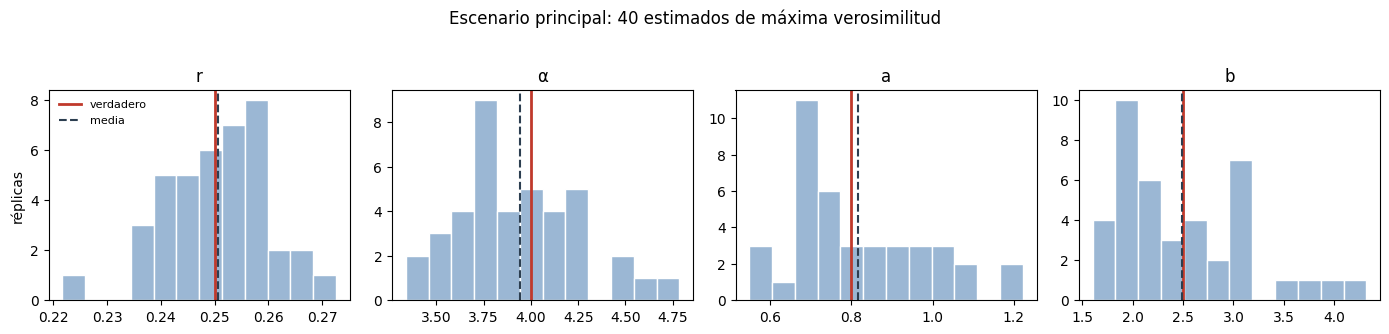

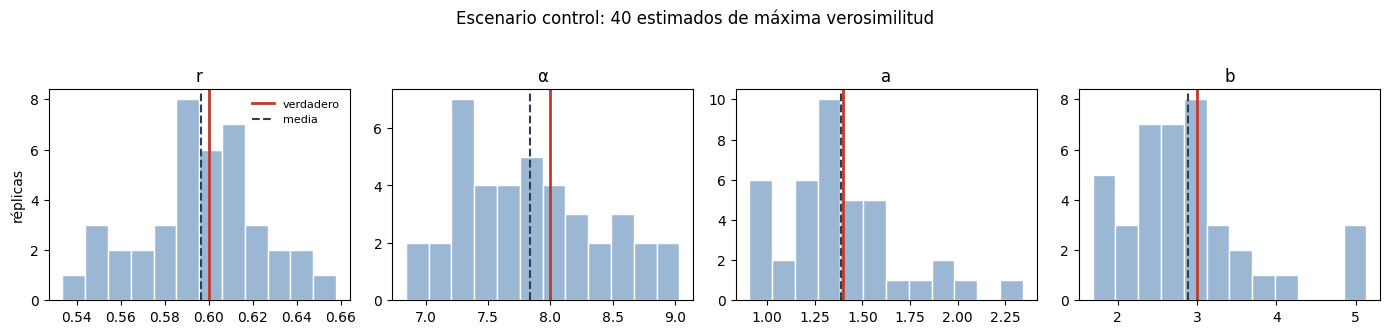

In [6]:
ETIQUETAS = {"r": "r", "alpha": "α", "a": "a", "b": "b"}

for nombre, df in resultados.items():
    fig, ejes = plt.subplots(1, 4, figsize=(14, 3.2))
    for eje, k in zip(ejes, NOMBRES):
        eje.hist(df[k], bins=12, color="#9bb7d4", edgecolor="white")
        eje.axvline(ESCENARIOS[nombre][k], color="#c0392b", lw=2, label="verdadero")
        eje.axvline(df[k].mean(), color="#2c3e50", lw=1.5, ls="--", label="media")
        eje.set_title(ETIQUETAS[k])
    ejes[0].set_ylabel("réplicas")
    ejes[0].legend(frameon=False, fontsize=8)
    fig.suptitle(f"Escenario {nombre}: 40 estimados de máxima verosimilitud", y=1.03)
    fig.tight_layout()
    fig.savefig(f"../figs/parte1_histogramas_{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

### Revisión de los criterios de éxito

In [7]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sim = simular_clientes(2357, ESCENARIOS["principal"], np.random.default_rng(77785))
    bgf_sim = BetaGeoFitter().fit(sim["x"], sim["tx"], sim["T"])
propio_77785 = resultados["principal"].set_index("semilla").loc[77785, list(NOMBRES)]
dif_lifetimes = (propio_77785 - bgf_sim.params_[list(NOMBRES)]).abs().max()

criterios = []
for nombre, df in resultados.items():
    t = tablas[nombre]
    criterios.append({
        "escenario": nombre,
        "1. ningún parámetro en la cota": bool((np.abs(np.log(df[list(NOMBRES)])) < 10 - 1e-3).all().all()),
        "2. |sesgo relativo| < 10 % (máx.)": f"{t['sesgo relativo (%)'].abs().max():.1f} %",
        "3. verdadero en media ± 2DE": bool(t["verdadero en media ± 2DE"].all()),
        "4. LL(estimado) ≥ LL(verdadero) en las 40": bool((df["ll_est"] >= df["ll_verdadero"]).all()),
    })
display(pd.DataFrame(criterios).set_index("escenario").T)
print("5. Semilla 77785, escenario principal: diferencia máxima con lifetimes =",
      f"{dif_lifetimes:.1e}")
pd.DataFrame({"src/bgnbd.py": propio_77785, "lifetimes": bgf_sim.params_[list(NOMBRES)]}).round(4)

escenario,principal,control
1. ningún parámetro en la cota,True,True
2. |sesgo relativo| < 10 % (máx.),2.1 %,3.7 %
3. verdadero en media ± 2DE,True,True
4. LL(estimado) ≥ LL(verdadero) en las 40,True,True


5. Semilla 77785, escenario principal: diferencia máxima con lifetimes = 2.2e-06


,src/bgnbd.py,lifetimes
r,0.2217,0.2217
alpha,3.3377,3.3377
a,1.0166,1.0166
b,3.0315,3.0315


### ¿Qué parámetros se estiman con más precisión?

Para comparar parámetros de distinta magnitud usamos la DE relativa al valor verdadero (columna *DE / verdadero*). Además vemos qué tan correlacionados salen los estimados entre réplicas y qué tan bien se estiman dos combinaciones con significado directo: la tasa media de compra $E[\lambda] = r/\alpha$ y la probabilidad media de morir $E[p] = a/(a+b)$.

In [8]:
filas = []
for nombre, df in resultados.items():
    v = ESCENARIOS[nombre]
    comb = pd.DataFrame({"r/α": df["r"] / df["alpha"], "a/(a+b)": df["a"] / (df["a"] + df["b"])})
    verdad = {"r/α": v["r"] / v["alpha"], "a/(a+b)": v["a"] / (v["a"] + v["b"])}
    filas.append({
        "escenario": nombre,
        "corr(r, α)": df["r"].corr(df["alpha"]),
        "corr(a, b)": df["a"].corr(df["b"]),
        "DE/verdadero r/α (%)": 100 * comb["r/α"].std() / verdad["r/α"],
        "DE/verdadero a/(a+b) (%)": 100 * comb["a/(a+b)"].std() / verdad["a/(a+b)"],
    })
pd.DataFrame(filas).set_index("escenario").round(3)

,"corr(r, α)","corr(a, b)",DE/verdadero r/α (%),DE/verdadero a/(a+b) (%)
escenario,,,,
principal,0.734,0.946,6.018,7.017
control,0.875,0.967,3.999,5.119


### Conclusiones de 1.3

**El estimador funciona.** En los dos escenarios se cumplen los cinco criterios de la propuesta: ningún parámetro llega a la cota, el sesgo relativo más grande es de 2.1 % (principal) y 3.7 % (control), el valor verdadero siempre cae dentro de media ± 2 DE, el optimizador encuentra una log-verosimilitud mayor o igual que la de los parámetros verdaderos en las 80 réplicas, y con la semilla 77785 los estimados coinciden con `lifetimes` hasta el sexto decimal. Con esto podemos usar `ajustar_bgnbd` en CDNOW con confianza.

**r y α se estiman mucho mejor que a y b.** La DE relativa de $r$ es de aproximadamente 4 % y la de $\alpha$ de 7–8 %, mientras que la de $a$ ronda el 21–22 % y la de $b$ el 27 %, en ambos escenarios. La razón está en la verosimilitud:

- **Las compras se observan directamente.** Cada uno de los 2 357 clientes, incluidos los que no repiten, informa sobre $\lambda$: el término $\frac{\Gamma(r+x)\alpha^r}{\Gamma(r)(\alpha+T)^{r+x}}$ aparece en todos. Hay mucha información sobre cuántas compras se hacen y qué tan dispersas están entre clientes, que es justo lo que miden $r$ y $\alpha$.
- **La muerte nunca se observa.** Solo se infiere de forma indirecta: un cliente que compraba seguido y dejó de comprar *probablemente* murió. Además, como vimos en 1.1, **los clientes con $x = 0$ no aportan nada sobre $p$**: con $x = 0$ el factor beta vale $B(a,b)/B(a,b) = 1$. En CDNOW son 1 411 de 2 357 (60 %), así que $a$ y $b$ se estiman con una fracción de la muestra.

**a y b están casi confundidos entre sí, pero su combinación no.** La correlación entre los estimados de $a$ y $b$ en las 40 réplicas es de 0.95–0.97: cuando el optimizador sube $a$ también sube $b$. Los datos identifican bien la probabilidad media de morir, $E[p] = a/(a+b)$ (DE relativa de 5–7 %), pero no tanto la *forma* de la distribución de $p$ (si los clientes son parecidos o muy distintos en su propensión a irse). Lo mismo, en menor grado, pasa con $r$ y $\alpha$ (correlación de 0.73–0.88).

**Para el resto del proyecto:** al interpretar el ajuste de CDNOW (2.2) conviene dar más peso a $r/\alpha$ y a $a/(a+b)$ que a $a$ y $b$ por separado, y el error estándar por bootstrap de $a$ y $b$ (2.3) debería salir claramente más grande que el de $r$ y $\alpha$.
